# Quantum Neural Networks (QNN)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mateo-Giacometti/tp_computacion_cuantica/blob/main/qnn/notebooks/qnn.ipynb)

En este notebook se desarrolla de forma breve y autocontenida la sección de **Quantum Neural Networks (QNN)** del trabajo práctico de Computación Cuántica sobre Quantum Machine Learning. Siguiendo la estructura de las diapositivas de la sección 3, se implementa en [PennyLane](https://docs.pennylane.ai/) el circuito variacional completo, se verifica la estimación de $\langle Z \rangle$ con *shots* y la regla de *parameter shift*, se entrena la red sobre un problema clásico no lineal y se reproduce el fenómeno de *barren plateaus*.

1. Estructura de una QNN: codificación, ansatz y medición $\langle Z \rangle$
2. Entrenamiento híbrido y regla de *parameter shift*
3. Clasificación no lineal (XOR 2D) y rol del entrelazamiento
4. Limitación en la optimización: *barren plateaus*

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/tp_computacion_cuantica")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Mateo-Giacometti/tp_computacion_cuantica.git", str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=False)
    if importlib.util.find_spec("pennylane") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pennylane>=0.45"], check=True)
    BASE_DIR = REPO_DIR / "qnn"
else:
    BASE_DIR = Path("..").resolve()

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from src import datasets as ds, plots as pl

FIGURES_DIR = pl.init_environment(BASE_DIR / "figuras")

## 1. Estructura de una QNN: codificación, ansatz y medición

Una Quantum Neural Network procesa un vector clásico $\mathbf{x} = (x_1, \dots, x_n)$ mediante un circuito cuántico parametrizado de tres etapas ([Cerezo et al., 2021](https://arxiv.org/abs/2012.09265)):

1. **Codificación $U(\mathbf{x})|0\dots 0\rangle$:** regla fija que mapea las características clásicas a un estado cuántico (por ejemplo, rotaciones $R_Y(x_i)$ en cada qubit).
2. **Ansatz $W(\boldsymbol{\theta})$:** $L$ capas entrenables formadas por rotaciones $R_Y(\theta)$ y $R_Z(\theta)$ (los pesos) seguidas de compuertas `CNOT` en cadena (las conexiones que entrelazan los qubits), totalizando $2 \cdot n \cdot L$ parámetros. En la esfera de Bloch, $R_Y$ modifica la altura del estado y por ende $\langle Z \rangle$, mientras que $R_Z$ ajusta la fase relativa entre $|0\rangle$ y $|1\rangle$.
3. **Medición $\langle Z \rangle$:** al medir el último qubit en la base computacional se obtiene un bit ($0 \to +1$, $1 \to -1$). Repitiendo el circuito $S$ veces (*shots*) y contando $n_0$ ceros y $n_1$ unos se estima la predicción continua en $[-1, 1]$:

$$f(\mathbf{x}; \boldsymbol{\theta}) = \langle Z \rangle \approx \frac{n_0 - n_1}{S}$$

En la siguiente celda definimos este circuito para $n = 2$ qubits y $L = 2$ capas, lo dibujamos y comparamos su salida exacta contra la estimación empírica con $S = 1000$ *shots*.

Valor esperado exacto <Z>         = -0.4532
Con S = 1000 shots (n0=287, n1=713) -> (n0 - n1)/S = -0.4260


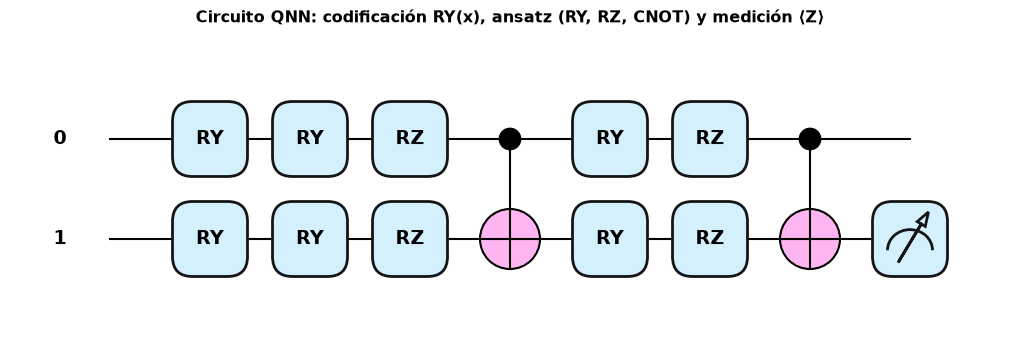

In [2]:
N_QUBITS, N_LAYERS = 2, 2
dev_exact = qml.device("default.qubit", wires=N_QUBITS)


def qnn_circuit(x, weights, entangle=True):
    # 1. Codificación: cada feature entra como ángulo de rotación RY
    for i in range(N_QUBITS):
        qml.RY(x[i], wires=i)
    # 2. Ansatz: L capas de rotaciones RY, RZ y cadena de CNOT
    for layer in range(N_LAYERS):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)
        if entangle:
            for i in range(N_QUBITS - 1):
                qml.CNOT(wires=[i, i + 1])


@qml.qnode(dev_exact, interface="autograd")
def qnn_forward(x, weights):
    qnn_circuit(x, weights, entangle=True)
    return qml.expval(qml.PauliZ(N_QUBITS - 1))


@qml.set_shots(1000)
@qml.qnode(qml.device("default.qubit", wires=N_QUBITS, seed=42))
def qnn_sample_z(x, weights):
    qnn_circuit(x, weights, entangle=True)
    return qml.sample(qml.PauliZ(N_QUBITS - 1))


rng = np.random.default_rng(3)
w_demo = pnp.array(rng.uniform(-np.pi, np.pi, size=(N_LAYERS, N_QUBITS, 2)), requires_grad=True)
x_demo = np.array([0.8, -0.6])

exact_val = float(qnn_forward(x_demo, w_demo))
samples = np.asarray(qnn_sample_z(x_demo, w_demo))
n0, n1 = int(np.sum(samples == 1)), int(np.sum(samples == -1))
est_val = (n0 - n1) / len(samples)

print(f"Valor esperado exacto <Z>         = {exact_val:+.4f}")
print(f"Con S = {len(samples)} shots (n0={n0}, n1={n1}) -> (n0 - n1)/S = {est_val:+.4f}")

pl.plot_qnn_circuit(qnn_forward, x_demo, w_demo, FIGURES_DIR / "01_circuito_qnn.png")

## 2. Entrenamiento híbrido y regla de *parameter shift*

Para ajustar los ángulos $\boldsymbol{\theta}$ sobre un conjunto de entrenamiento $\{(\mathbf{x}_i, y_i)\}_{i=1}^N$ con $y_i \in \{-1, +1\}$, la computadora clásica minimiza una pérdida clásica como el error cuadrático medio (MSE):

$$L(\boldsymbol{\theta}) = \frac{1}{N} \sum_{i=1}^{N} \big(f(\mathbf{x}_i; \boldsymbol{\theta}) - y_i\big)^2, \qquad \frac{\partial L}{\partial \boldsymbol{\theta}} = \frac{1}{N} \sum_{i=1}^{N} 2\big(f_i - y_i\big) \frac{\partial f_i}{\partial \boldsymbol{\theta}}$$

Como medir un estado cuántico intermedio lo destruye, no es posible guardar activaciones ni aplicar *backpropagation* dentro de la QPU. En su lugar, dado que $f$ depende de cada ángulo de rotación de forma sinusoidal, la derivada exacta se obtiene evaluando el mismo circuito en dos ángulos desplazados mediante la regla de *parameter shift* ([Mitarai et al., 2018](https://arxiv.org/abs/1803.00745); [Schuld et al., 2019](https://arxiv.org/abs/1811.11184)):

$$\frac{\partial f}{\partial \theta_k} = \frac{f(\theta_k + \frac{\pi}{2}) - f(\theta_k - \frac{\pi}{2})}{2}$$

Esto implica evaluar $2P$ circuitos desplazados por cada muestra (o $(2P + 1) \cdot S \cdot N$ ejecuciones por paso de optimización contando $f(\boldsymbol{\theta})$). Comprobamos numéricamente que la regla coincide con el gradiente exacto de PennyLane.

Gradiente por parameter shift = -0.1475514919
Gradiente automático PennyLane = -0.1475514919
Diferencia absoluta            = 1.39e-16


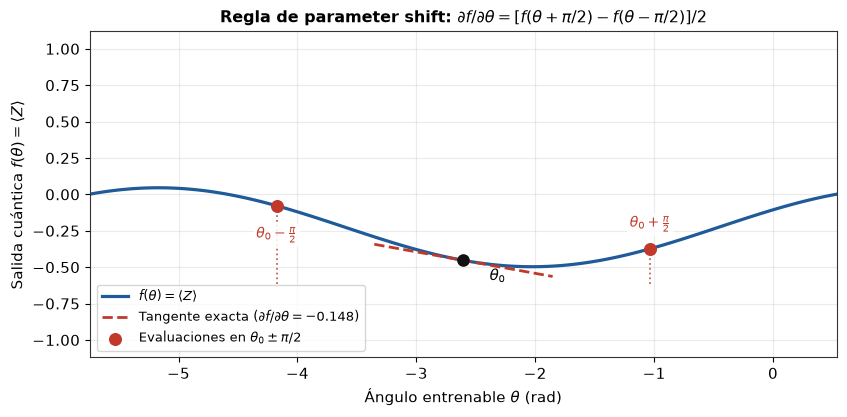

In [3]:
idx = (0, 0, 0)  # primer parámetro RY de la capa 0
w_plus, w_minus = w_demo.copy(), w_demo.copy()
w_plus[idx] += np.pi / 2
w_minus[idx] -= np.pi / 2

f0 = float(qnn_forward(x_demo, w_demo))
f_plus = float(qnn_forward(x_demo, w_plus))
f_minus = float(qnn_forward(x_demo, w_minus))

grad_shift = 0.5 * (f_plus - f_minus)
grad_auto = float(qml.grad(qnn_forward, argnums=1)(x_demo, w_demo)[idx])
print(f"Gradiente por parameter shift = {grad_shift:+.10f}")
print(f"Gradiente automático PennyLane = {grad_auto:+.10f}")
print(f"Diferencia absoluta            = {abs(grad_shift - grad_auto):.2e}")

theta0 = float(w_demo[idx])
thetas = np.linspace(theta0 - np.pi, theta0 + np.pi, 120)
f_curve = []
for th in thetas:
    w_tmp = w_demo.copy()
    w_tmp[idx] = th
    f_curve.append(float(qnn_forward(x_demo, w_tmp)))

pl.plot_parameter_shift(
    thetas, np.array(f_curve), theta0, f0, f_plus, f_minus, grad_shift,
    FIGURES_DIR / "02_parameter_shift.png",
)

## 3. Clasificación no lineal (XOR 2D) y rol del entrelazamiento

En la literatura introductoria de QML, las QNN se evalúan habitualmente en problemas supervisados de baja dimensión que ponen a prueba su capacidad para construir fronteras no lineales o combinar características, como la función de paridad (XOR), datasets geométricos 2D (*circles*, *moons*), subconjuntos de *Iris* o regresión de funciones periódicas ([Schuld y Petruccione, 2021](https://doi.org/10.1007/978-3-030-83098-4)).

Aquí resolvemos un **problema XOR 2D (cuadrantes alternados)**: la clase $+1$ agrupa los cuadrantes I y III ($x_1 x_2 > 0$) y la clase $-1$ los cuadrantes II y IV ($x_1 x_2 < 0$). Es el caso canónico que un modelo lineal clásico no puede separar y permite ver directamente el papel de las compuertas `CNOT`:

- **Sin `CNOT`:** el qubit medido ($q_1$) nunca interactúa con $q_0$, por lo que la salida ignora $x_1$ y no puede resolver XOR.
- **Con `CNOT`:** el entrelazamiento acopla ambos qubits y permite aprender la frontera no lineal con solo $2 \cdot 2 \cdot 2 = 8$ parámetros entrenables.

Precisión en test | Lineal clásico   : 47.9%
Precisión en test | QNN sin CNOT     : 47.9%
Precisión en test | QNN con CNOT     : 100.0%  (8 parámetros)
Precisión en test | MLP clásica (8u) : 100.0%


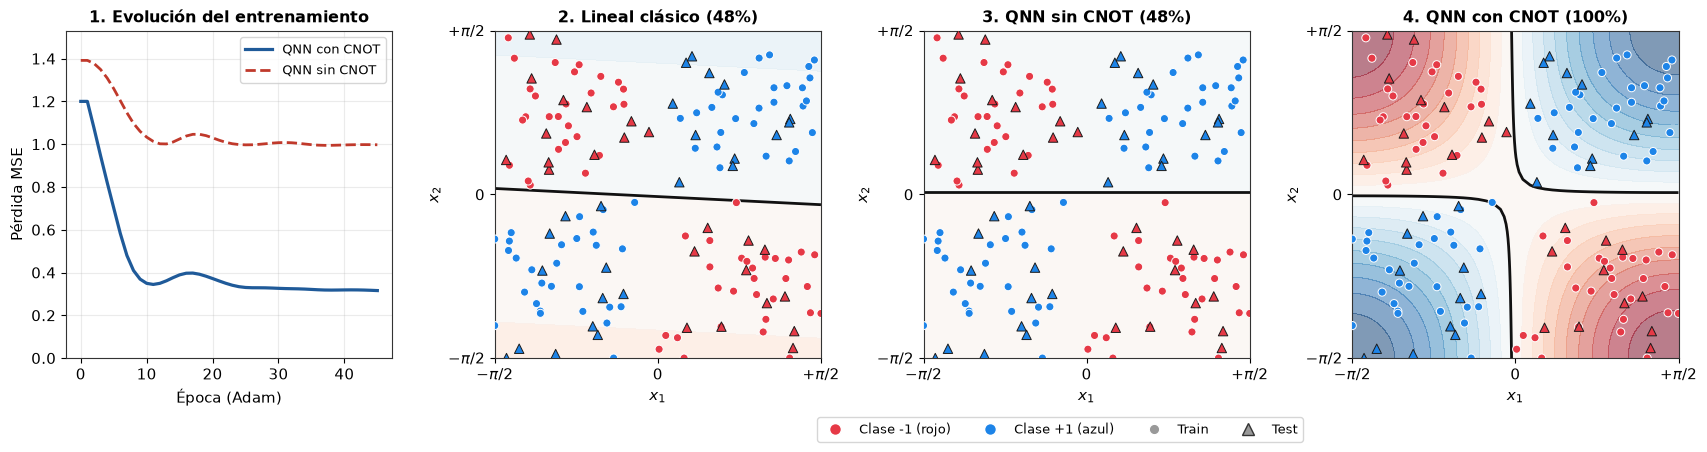

In [4]:
X_train, X_test, y_train, y_test = ds.make_xor_quadrants(n_samples=160, seed=42)
X_tr_p = pnp.array(X_train, requires_grad=False)
y_tr_p = pnp.array(y_train, dtype=float, requires_grad=False)


@qml.qnode(dev_exact, interface="autograd")
def qnn_no_ent(x, weights):
    qnn_circuit(x, weights, entangle=False)
    return qml.expval(qml.PauliZ(N_QUBITS - 1))


def train_qnn(model, n_epochs=45, lr=0.12, seed=0):
    rng_local = np.random.default_rng(seed)
    weights = pnp.array(rng_local.uniform(-0.8, 0.8, size=(N_LAYERS, N_QUBITS, 2)), requires_grad=True)
    opt = qml.AdamOptimizer(stepsize=lr)

    def loss_fn(w):
        preds = pnp.stack([model(x, w) for x in X_tr_p])
        return pnp.mean((preds - y_tr_p) ** 2)

    losses = [float(loss_fn(weights))]
    for _ in range(n_epochs):
        weights, loss_val = opt.step_and_cost(loss_fn, weights)
        losses.append(float(loss_val))
    return weights, losses


w_ent, losses_ent = train_qnn(qnn_forward, n_epochs=45, lr=0.12, seed=0)
w_no_ent, losses_no_ent = train_qnn(qnn_no_ent, n_epochs=45, lr=0.12, seed=0)

pred_qnn_ent = lambda X: np.array([float(qnn_forward(x, w_ent)) for x in X])
pred_qnn_no_ent = lambda X: np.array([float(qnn_no_ent(x, w_no_ent)) for x in X])

clf_linear = LogisticRegression().fit(X_train, y_train)
clf_mlp = MLPClassifier(hidden_layer_sizes=(8,), max_iter=1500, random_state=0).fit(X_train, y_train)

acc_lin = clf_linear.score(X_test, y_test)
acc_no_ent = np.mean(np.sign(pred_qnn_no_ent(X_test)) == y_test)
acc_ent = np.mean(np.sign(pred_qnn_ent(X_test)) == y_test)
acc_mlp = clf_mlp.score(X_test, y_test)

print(f"Precisión en test | Lineal clásico   : {acc_lin:.1%}")
print(f"Precisión en test | QNN sin CNOT     : {acc_no_ent:.1%}")
print(f"Precisión en test | QNN con CNOT     : {acc_ent:.1%}  (8 parámetros)")
print(f"Precisión en test | MLP clásica (8u) : {acc_mlp:.1%}")

pl.plot_training_and_boundaries(
    losses_ent, losses_no_ent, X_train, X_test, y_train, y_test,
    predict_fns=[
        lambda X: 2 * clf_linear.predict_proba(X)[:, 1] - 1,
        pred_qnn_no_ent,
        pred_qnn_ent,
    ],
    titles=[
        f"2. Lineal clásico ({acc_lin:.0%})",
        f"3. QNN sin CNOT ({acc_no_ent:.0%})",
        f"4. QNN con CNOT ({acc_ent:.0%})",
    ],
    output_path=FIGURES_DIR / "03_entrenamiento_y_fronteras_qnn.png",
)

## 4. Limitación en la optimización: *barren plateaus*

Al escalar una QNN a muchos qubits o circuitos profundos aparece el principal cuello de botella de su entrenamiento: las **mesetas estériles** o *barren plateaus* ([McClean et al., 2018](https://arxiv.org/abs/1803.11173)). Para visualizarlo directamente, reproducimos el circuito de paridad de la diapositiva 27: cada qubit $q_i$ aplica $R_X(x_i)$ y $R_Y(\theta_i)$, seguido de una cadena de `CNOT` que concentra la paridad global en el último qubit $q_n$.

Cada qubit aporta $c_i = \langle Z_i \rangle = \cos x_i \cos \theta_i \in [-1, 1]$, por lo que la salida y su derivada respecto de $\theta_1$ se factorizan como:

$$f = c_1 c_2 \cdots c_n, \qquad \frac{\partial f}{\partial \theta_1} = (-\cos x_1 \sin \theta_1) \cdot c_2 c_3 \cdots c_n$$

Al multiplicar $n - 1$ factores con $|c_i| < 1$, la varianza del gradiente cae exponencialmente como $4^{-n}$. Cuando el gradiente cae por debajo del ruido de estimación de *shots* ($\sim 1/\sqrt{S}$), el optimizador clásico percibe un paisaje plano y deja de aprender.

n =  2 qubits | Var[df/dtheta_1] = 5.52e-02  (teórico 4^-n = 6.25e-02)
Verificación analítica (n=4) | circuito=+0.004380 | prod(c_i)=+0.004380
n =  4 qubits | Var[df/dtheta_1] = 1.70e-03  (teórico 4^-n = 3.91e-03)


n =  6 qubits | Var[df/dtheta_1] = 9.27e-05  (teórico 4^-n = 2.44e-04)


n =  8 qubits | Var[df/dtheta_1] = 1.23e-05  (teórico 4^-n = 1.53e-05)


n = 10 qubits | Var[df/dtheta_1] = 1.42e-07  (teórico 4^-n = 9.54e-07)


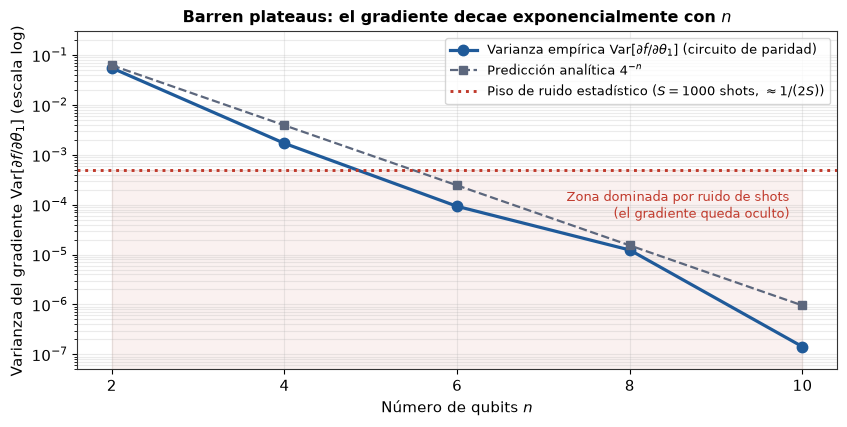

In [5]:
rng_bp = np.random.default_rng(123)
qubit_counts = [2, 4, 6, 8, 10]
n_samples = 120
shots_ref = 1000
emp_vars = []

for n_q in qubit_counts:
    dev_n = qml.device("default.qubit", wires=n_q)

    @qml.qnode(dev_n)
    def parity_qnn(x, theta):
        for i in range(n_q):
            qml.RX(x[i], wires=i)
            qml.RY(theta[i], wires=i)
        for i in range(n_q - 1):
            qml.CNOT(wires=[i, i + 1])
        return qml.expval(qml.PauliZ(n_q - 1))

    grads = []
    for k in range(n_samples):
        x = rng_bp.uniform(0, 2 * np.pi, size=n_q)
        th = rng_bp.uniform(0, 2 * np.pi, size=n_q)
        th_p, th_m = th.copy(), th.copy()
        th_p[0] += np.pi / 2
        th_m[0] -= np.pi / 2
        g_shift = 0.5 * (float(parity_qnn(x, th_p)) - float(parity_qnn(x, th_m)))
        grads.append(g_shift)

        if k == 0 and n_q == 4:
            analytic = np.prod(np.cos(x) * np.cos(th))
            print(f"Verificación analítica (n=4) | circuito={float(parity_qnn(x, th)):+.6f} | prod(c_i)={analytic:+.6f}")

    var_g = float(np.var(grads))
    emp_vars.append(var_g)
    print(f"n = {n_q:2d} qubits | Var[df/dtheta_1] = {var_g:.2e}  (teórico 4^-n = {4.0 ** (-n_q):.2e})")

exact_vars = [4.0 ** (-n_q) for n_q in qubit_counts]
shot_noise_var = 1.0 / (2 * shots_ref)

pl.plot_barren_plateaus(
    qubit_counts, emp_vars, exact_vars, shot_noise_var, shots_ref,
    FIGURES_DIR / "04_barren_plateaus.png",
)

## Referencias

1. Bowles, J., Ahmed, S. y Schuld, M. (2024). *Better than classical? The subtle art of benchmarking quantum machine learning models*. [arXiv:2403.07059](https://arxiv.org/abs/2403.07059)
2. Cerezo, M., Arrasmith, A., Babbush, R., Benjamin, S. C., Endo, S., Fujii, K., McClean, J. R., Mitarai, K., Yuan, X., Cincio, L. y Coles, P. J. (2021). *Variational quantum algorithms*. Nature Reviews Physics, 3, 625–644. [arXiv:2012.09265](https://arxiv.org/abs/2012.09265)
3. McClean, J. R., Boixo, S., Smelyanskiy, V. N., Babbush, R. y Neven, H. (2018). *Barren plateaus in quantum neural network training landscapes*. Nature Communications, 9, 4812. [arXiv:1803.11173](https://arxiv.org/abs/1803.11173)
4. Mitarai, K., Negoro, M., Kitagawa, M. y Fujii, K. (2018). *Quantum circuit learning*. Physical Review A, 98, 032309. [arXiv:1803.00745](https://arxiv.org/abs/1803.00745)
5. Pérez-Salinas, A., Cervera-Lierta, A., Gil-Fuster, E. y Latorre, J. I. (2020). *Data re-uploading for a universal quantum classifier*. Quantum, 4, 226. [arXiv:1907.02085](https://arxiv.org/abs/1907.02085)
6. Schuld, M., Bergholm, V., Gogolin, C., Izaac, J. y Killoran, N. (2019). *Evaluating analytic gradients on quantum hardware*. Physical Review A, 99, 032331. [arXiv:1811.11184](https://arxiv.org/abs/1811.11184)
7. Schuld, M. y Petruccione, F. (2021). *Machine Learning with Quantum Computers* (2.ª ed.). Springer. [DOI 10.1007/978-3-030-83098-4](https://doi.org/10.1007/978-3-030-83098-4)